In [3]:
!pip install pandas numpy matplotlib openpyxl opencv-python wordcloud gradio

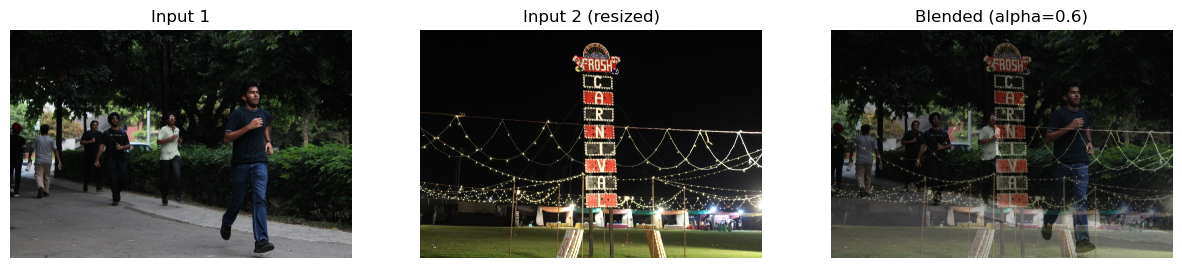

In [9]:
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread('image1.jpg')
img2 = cv2.imread('image2.jpg')
# cv2.imread returns None silently on a bad path, so fail loudly instead
assert img1 is not None and img2 is not None, "Check image file names/paths"

# Resize img2 to img1's size. cv2.resize takes (width, height), not (height, width)
h, w = img1.shape[:2]
img2 = cv2.resize(img2, (w, h), interpolation=cv2.INTER_AREA)

alpha = 0.6
blended = cv2.addWeighted(img1, alpha, img2, 1 - alpha, 0)  # 0.6*img1 + 0.4*img2 + 0

cv2.imwrite('Exercise2_input1.jpg', img1)
cv2.imwrite('Exercise2_input2.jpg', img2)
cv2.imwrite('Exercise2_blended.jpg', blended)

# Show with matplotlib. cv2.imshow often freezes Jupyter kernels.
# OpenCV loads images as BGR, so convert to RGB or the colours will be wrong.
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [img1, img2, blended],
                    ['Input 1', 'Input 2 (resized)', f'Blended (alpha={alpha})']):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis('off')
plt.savefig('Exercise2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()